# Hostinger marketing attribution: analysis notebook

Independent case study for Hostinger's Marketing Data Analyst role. **SIMULATED data** (seed 42), calibrated on public hostinger.com facts (prices, 30-day money-back guarantee, affiliate terms) listed in `data/SOURCES.md`. Not Hostinger data, not affiliated with Hostinger.

SQL (folder `sql/`) does the heavy lifting: paths, rule-based attribution, customer value, scorecards, data quality.
This notebook only does what SQL does badly:

1. **Markov attribution** (removal effect), coded by hand
2. **Geo test**: difference-in-differences on brand ads, with a bootstrap confidence interval
3. **Influencer halo**: do brand searches rise after a video?
4. **Response curves** and a budget **reallocation** simulation
5. A small **anomaly detection** on tracking and promo codes

Run `python src/generate_sim.py` then `python src/run_sql.py` first.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import duckdb
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
OUT = ROOT / "data" / "output"
CLEAN = ROOT / "data" / "clean"
rng = np.random.default_rng(42)
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 20)

## 1 · Markov attribution (data-driven)

Each prospect's journey is a chain: `Start → channel → channel → … → Conversion` (or `Null` if they never buy).
From all journeys (128k buyers **and** ~1.2M non-buyers) we count how often people move from one state to the next. That gives a **transition matrix**.

**Removal effect** of a channel = how much the overall conversion probability drops if that channel disappeared
(everyone who would have reached it goes to `Null` instead). A channel's credit is its removal effect divided by the sum of all removal effects.

The paths come from SQL (`02_conversion_paths.sql`, output `markov_paths`).

In [2]:
paths = pd.read_csv(OUT / "markov_paths.csv")
print(f"{len(paths):,} distinct paths, {paths.conversions.sum():,} conversions, {paths.non_conversions.sum():,} non-conversions")
paths.head()

18,775 distinct paths, 126,843.0 conversions, 1,176,522.0 non-conversions


,path,conversions,non_conversions
0,PPC Non-brand,12703.0,263183.0
1,SEO,14849.0,198237.0
2,Affiliates - Content,6270.0,52818.0
3,Direct,5922.0,46352.0
4,PPC Brand,4829.0,36132.0


In [3]:
# 1) count transitions between consecutive states, weighted by how many people took that path
transitions = {}
for path, conv, null in paths.itertuples(index=False):
    steps = ["Start"] + path.split(" > ")
    for a, b in zip(steps[:-1], steps[1:]):
        transitions[(a, b)] = transitions.get((a, b), 0) + conv + null
    if conv:
        transitions[(steps[-1], "Conversion")] = transitions.get((steps[-1], "Conversion"), 0) + conv
    if null:
        transitions[(steps[-1], "Null")] = transitions.get((steps[-1], "Null"), 0) + null

channels = sorted({s for pair in transitions for s in pair} - {"Start", "Conversion", "Null"})
states = ["Start"] + channels + ["Conversion", "Null"]
idx = {s: i for i, s in enumerate(states)}

# 2) transition matrix: each row sums to 1 (probability of the next state)
P = np.zeros((len(states), len(states)))
for (a, b), n in transitions.items():
    P[idx[a], idx[b]] += n
P[idx["Conversion"], idx["Conversion"]] = 1      # absorbing states stay where they are
P[idx["Null"], idx["Null"]] = 1
P = P / P.sum(axis=1, keepdims=True)

def conversion_probability(P):
    """Probability of ending in Conversion when starting from Start (absorbing Markov chain).
    Q = moves between transient states, R = moves into Conversion / Null.
    B = (I - Q)^-1 R gives the absorption probabilities."""
    transient = [idx["Start"]] + [idx[c] for c in channels]
    Q = P[np.ix_(transient, transient)]
    R = P[np.ix_(transient, [idx["Conversion"]])]
    B = np.linalg.solve(np.eye(len(transient)) - Q, R)
    return B[0, 0]

base = conversion_probability(P)
removal = {}
for c in channels:
    P_removed = P.copy()
    P_removed[idx[c], :] = 0
    P_removed[idx[c], idx["Null"]] = 1            # whoever reaches c is lost
    removal[c] = 1 - conversion_probability(P_removed) / base

markov = (pd.Series(removal, name="removal_effect").to_frame()
          .assign(markov_share=lambda d: d.removal_effect / d.removal_effect.sum())
          .sort_values("markov_share", ascending=False))
print(f"Baseline conversion probability: {base:.2%}")
markov.round(3)

Baseline conversion probability: 9.73%


,removal_effect,markov_share
SEO,0.440,0.232
PPC Non-brand,0.366,0.193
Direct,0.321,0.170
PPC Brand,0.221,0.117
Affiliates - Coupon,0.207,0.109
Affiliates - Content,0.174,0.092
Email,0.114,0.060
Influencers,0.050,0.026


**From channel totals to order-level credit.** To use Markov in the same Power BI model as the rule-based models,
each order's credit (1) is split across the channels in its own path, in proportion to their removal effects.
The channel list per order is taken from the linear model (every channel in the path has linear credit > 0).

In [4]:
rule = pd.read_csv(OUT / "attribution_rule_based.csv")
in_path = rule[rule.model == "Linear"][["order_id", "channel"]].copy()
in_path["weight"] = in_path.channel.map(markov.removal_effect).fillna(1.0)   # 'Unattributed' keeps 1
in_path["credit"] = in_path.weight / in_path.groupby("order_id").weight.transform("sum")
markov_orders = in_path.assign(model="Markov (data-driven)")[["order_id", "model", "channel", "credit"]]

credits = pd.concat([rule, markov_orders], ignore_index=True)
assert np.allclose(credits.groupby(["order_id", "model"]).credit.sum(), 1.0)   # 1 credit per order and model
credits.to_csv(OUT / "attribution_credits.csv", index=False)

share = (credits.pivot_table(index="channel", columns="model", values="credit", aggfunc="sum")
         / credits.order_id.nunique())
order = ["Last click", "First click", "Linear", "Time decay", "Position 40/20/40", "Markov (data-driven)"]
share = share[order].sort_values("Last click", ascending=False)
share.round(3)

model,Last click,First click,Linear,Time decay,Position 40/20/40,Markov (data-driven)
channel,,,,,,
SEO,0.230,0.263,0.250,0.249,0.248,0.290
Direct,0.200,0.107,0.177,0.184,0.163,0.183
Affiliates - Coupon,0.165,0.048,0.092,0.096,0.101,0.083
PPC Brand,0.119,0.104,0.120,0.122,0.115,0.109
PPC Non-brand,0.104,0.271,0.165,0.154,0.178,0.181
Affiliates - Content,0.084,0.125,0.101,0.099,0.103,0.088
Email,0.059,0.000,0.041,0.045,0.034,0.023
Unattributed,0.020,0.020,0.020,0.020,0.020,0.020
Influencers,0.019,0.062,0.034,0.031,0.038,0.024


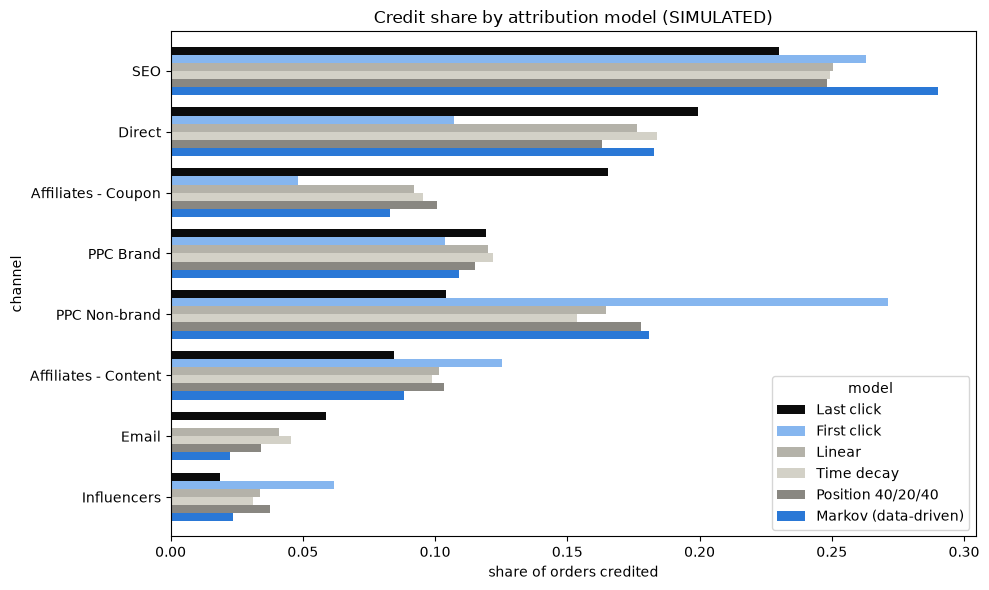

In [5]:
ax = share.drop(index="Unattributed").plot.barh(figsize=(10, 6), width=.8,
        color=["#0B0B0B", "#86B6EF", "#B4B2A9", "#D3D1C7", "#898781", "#2A78D6"])
ax.invert_yaxis(); ax.set_xlabel("share of orders credited"); ax.set_title("Credit share by attribution model (SIMULATED)")
plt.tight_layout(); plt.show()

In [6]:
summary = (share.reset_index().melt(id_vars="channel", var_name="model", value_name="credit_share"))
summary.to_csv(OUT / "attribution_summary.csv", index=False)
inf = share.loc["Influencers"]; brand = share.loc["PPC Brand"]; coupon = share.loc["Affiliates - Coupon"]
print(f"Influencers: {inf['Last click']:.1%} of orders under last click -> {inf['Markov (data-driven)']:.1%} under Markov "
      f"(x{inf['Markov (data-driven)'] / inf['Last click']:.1f})")
print(f"Coupon affiliates: {coupon['Last click']:.1%} under last click -> {coupon['Markov (data-driven)']:.1%} under Markov")
print(f"Brand search ads: {brand['Last click']:.1%} under last click -> {brand['Markov (data-driven)']:.1%} under Markov")

Influencers: 1.9% of orders under last click -> 2.4% under Markov (x1.3)
Coupon affiliates: 16.5% under last click -> 8.3% under Markov
Brand search ads: 11.9% under last click -> 10.9% under Markov


## 2 · Geo test: are brand search ads incremental?

Brand ads were **paused for 12 weeks** (2 Mar – 24 May 2026) in US, ES and ID (test) and kept running in FR, BR and IN (control). Other budgets and creator videos were frozen from 8 weeks before the test to its end, so the baseline is clean.

**Two outcomes**:
1. **Brand-search clicks** (paid ad + organic brand result): high volume, so a precise read of how many ad clicks come back through the organic result.
2. **Brand-search orders**: orders from buyers who searched the brand in the 30 days before buying, the only buyers brand ads can win or lose. Lower volume, so a wider interval: used as a check.

**Difference-in-differences (DiD)**: compare the change in the test countries with the change in the control countries over the same weeks.
The control group absorbs seasonality and anything else that hit every country.

`DiD = (log test, during − log test, before) − (log control, during − log control, before)`

If brand ads were 100% incremental, the test countries would lose every brand-search order that brand ads got as last click before the test.
**Incrementality** = observed loss ÷ that maximum loss. The rest was **recaptured** by the organic brand result.

In [7]:
geo = pd.read_csv(OUT / "geo_weekly.csv", parse_dates=["week"])
TEST_START, TEST_END = pd.Timestamp("2026-03-02"), pd.Timestamp("2026-05-24")
PRE_START = TEST_START - pd.Timedelta(weeks=8)           # 8-week clean baseline (budgets and videos frozen)
geo = geo[(geo.week >= PRE_START) & (geo.week <= TEST_END)].copy()
geo["phase"] = np.where(geo.week < TEST_START, "pre", "test")
weekly = geo.groupby(["group", "phase", "week"], as_index=False)[[
    "orders", "brand_search_orders", "orders_last_click_brand_ads", "brand_ad_clicks", "organic_brand_clicks"]].sum()
weekly["brand_clicks"] = weekly.brand_ad_clicks + weekly.organic_brand_clicks

def did(w, y):
    """Difference-in-differences on the log of the weekly average of column y."""
    m = w.groupby(["group", "phase"])[y].mean()
    return (np.log(m["test", "test"]) - np.log(m["test", "pre"])) - (np.log(m["control", "test"]) - np.log(m["control", "pre"]))

def bootstrap(w, y, n=5000):
    """Resample weeks with replacement. The same weeks are drawn for both groups,
    so seasonality shared by all countries stays paired."""
    wide = w.pivot(index="week", columns="group", values=y)
    phase = w.drop_duplicates("week").set_index("week").phase.loc[wide.index]
    pre_w, test_w = wide[phase == "pre"].values, wide[phase == "test"].values
    out = []
    for _ in range(n):
        a = pre_w[rng.integers(0, len(pre_w), len(pre_w))].mean(axis=0)     # columns: control, test
        b = test_w[rng.integers(0, len(test_w), len(test_w))].mean(axis=0)
        out.append((np.log(b[1]) - np.log(a[1])) - (np.log(b[0]) - np.log(a[0])))
    return np.array(out)

pre_test = weekly[(weekly.group == "test") & (weekly.phase == "pre")]

# 1) clicks: if no ad click came back, test countries would lose the whole paid share of brand clicks
paid_share = pre_test.brand_ad_clicks.sum() / pre_test.brand_clicks.sum()
click_effect = did(weekly, "brand_clicks")
clicks_lost = 1 - np.exp(click_effect)
clicks_lost_ci = 1 - np.exp(np.percentile(bootstrap(weekly, "brand_clicks"), [97.5, 2.5]))
incr, incr_ci = clicks_lost / paid_share, clicks_lost_ci / paid_share
print(f"Paid share of brand-search clicks before the test: {paid_share:.0%}")
print(f"Brand-search clicks lost when ads are off (DiD): {clicks_lost:.1%}  (95% CI {clicks_lost_ci[0]:.1%} to {clicks_lost_ci[1]:.1%})")
print(f"-> Incrementality of brand-ad clicks: {incr:.0%}  (95% CI {incr_ci[0]:.0%} to {incr_ci[1]:.0%}); "
      f"recaptured by the organic result: {1 - incr:.0%}")

# 2) orders, as a check
max_loss = pre_test.orders_last_click_brand_ads.sum() / pre_test.brand_search_orders.sum()

effect = did(weekly, "brand_search_orders")
boot = bootstrap(weekly, "brand_search_orders")
lost = 1 - np.exp(effect)
lost_ci = 1 - np.exp(np.percentile(boot, [97.5, 2.5]))
incr_orders, incr_orders_ci = lost / max_loss, lost_ci / max_loss

total_effect = did(weekly, "orders")
total_ci = 1 - np.exp(np.percentile(bootstrap(weekly, "orders"), [97.5, 2.5]))
print(f"Brand-search orders last-clicked by a brand ad before the test (max possible loss): {max_loss:.1%}")
print(f"Brand-search orders lost when ads are off (DiD): {lost:.1%}  (95% CI {lost_ci[0]:.1%} to {lost_ci[1]:.1%})")
print(f"-> Incrementality of brand-ad orders: {incr_orders:.0%}  (95% CI {incr_orders_ci[0]:.0%} to {incr_orders_ci[1]:.0%})")
print(f"All orders in test countries vs control: {-(1 - np.exp(total_effect)):+.1%}  (95% CI {-total_ci[1]:+.1%} to {-total_ci[0]:+.1%})")

Paid share of brand-search clicks before the test: 59%
Brand-search clicks lost when ads are off (DiD): 8.4%  (95% CI 2.8% to 13.4%)
-> Incrementality of brand-ad clicks: 14%  (95% CI 5% to 23%); recaptured by the organic result: 86%


Brand-search orders last-clicked by a brand ad before the test (max possible loss): 29.3%
Brand-search orders lost when ads are off (DiD): 3.8%  (95% CI -8.8% to 14.3%)
-> Incrementality of brand-ad orders: 13%  (95% CI -30% to 49%)
All orders in test countries vs control: -4.5%  (95% CI -9.5% to +0.7%)


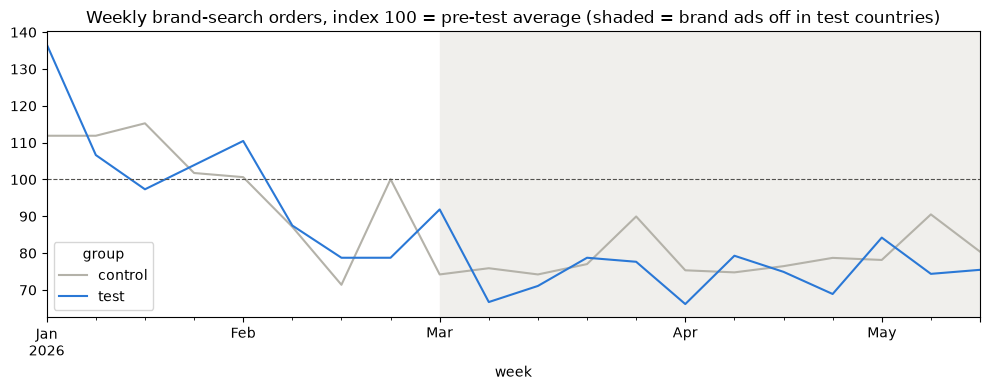

brand_ad_clicks  organic_brand_clicks
group   phase                                       
control pre              934.0                 602.0
        test             788.0                 536.0
test    pre              979.0                 684.0
        test               0.0                1314.0

In [8]:
# weekly series indexed to the pre-period average of each group (100 = normal)
idx_ = weekly.copy()
idx_["orders_index"] = 100 * idx_.brand_search_orders / idx_.groupby("group").brand_search_orders.transform(
    lambda s: s[idx_.loc[s.index, "phase"] == "pre"].mean())
pivot = idx_.pivot(index="week", columns="group", values="orders_index")
ax = pivot.plot(figsize=(10, 4), color={"control": "#B4B2A9", "test": "#2A78D6"})
ax.axvspan(TEST_START, TEST_END, color="#F0EFEC"); ax.axhline(100, ls="--", c="#52514E", lw=.8)
ax.set_title("Weekly brand-search orders, index 100 = pre-test average (shaded = brand ads off in test countries)")
plt.tight_layout(); plt.show()

clicks = weekly.groupby(["group", "phase"])[["brand_ad_clicks", "organic_brand_clicks"]].mean().round(0)
clicks

In [9]:
geo_series = idx_[["week", "group", "phase", "orders", "brand_search_orders", "orders_index", "brand_clicks", "brand_ad_clicks", "organic_brand_clicks"]]
geo_series.to_csv(OUT / "geo_did_weekly.csv", index=False)
geo_result = pd.DataFrame([
    ("Paid share of brand-search clicks before test", paid_share, np.nan, np.nan),
    ("Brand-search clicks lost when brand ads are off", clicks_lost, clicks_lost_ci[0], clicks_lost_ci[1]),
    ("Brand ads incrementality (clicks)", incr, incr_ci[0], incr_ci[1]),
    ("Ad clicks recaptured by the organic result", 1 - incr, 1 - incr_ci[1], 1 - incr_ci[0]),
    ("Brand-ads last-click share of brand-search orders before test", max_loss, np.nan, np.nan),
    ("Brand-search orders lost when brand ads are off", lost, lost_ci[0], lost_ci[1]),
    ("Brand ads incrementality (orders)", incr_orders, incr_orders_ci[0], incr_orders_ci[1]),
    ("All orders, test vs control", -(1 - np.exp(total_effect)), -total_ci[1], -total_ci[0]),
], columns=["metric", "value", "ci_low", "ci_high"])
geo_result.to_csv(OUT / "geo_result.csv", index=False)
geo_result.round(3)

,metric,value,ci_low,ci_high
0,Paid share of brand-search clicks before test,0.589,NaN,NaN
1,Brand-search clicks lost when brand ads are off,0.084,0.028,0.134
2,Brand ads incrementality (clicks),0.142,0.047,0.228
3,Ad clicks recaptured by the organic result,0.858,0.772,0.953
4,Brand-ads last-click share of brand-search ord...,0.293,NaN,NaN
5,Brand-search orders lost when brand ads are off,0.038,-0.088,0.143
6,Brand ads incrementality (orders),0.131,-0.299,0.487
7,"All orders, test vs control",-0.045,-0.095,0.007


## 3 · Influencer halo: brand searches after a video

Most viewers never click the creator's link: they search the brand later. Click-based attribution cannot see them.
Event study: for every video, brand searches (paid + organic brand clicks) in the creator's main country,
from 14 days before to 21 days after the publication date, indexed to the 14 days before.

Brand searches in the 14 days after a video: +43% vs the 14 days before


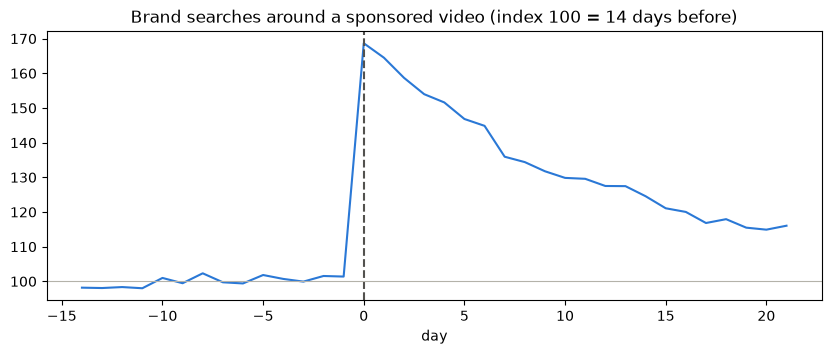

In [10]:
con = duckdb.connect()
brand_daily = con.execute(f'''
    SELECT country, CAST(ts AS DATE) AS date, COUNT(*) AS brand_searches
    FROM read_parquet('{(CLEAN / "sim_touchpoints.parquet").as_posix()}')
    WHERE channel = 'PPC Brand' OR sub_channel = 'Organic - brand'
    GROUP BY ALL
''').df()
brand_daily["date"] = pd.to_datetime(brand_daily.date)
videos = pd.read_csv(CLEAN / "sim_video_dates.csv", parse_dates=["video_date"]).merge(
    pd.read_csv(CLEAN / "sim_creators.csv")[["creator_id", "main_country", "audience_size"]], on="creator_id")

bd = brand_daily.set_index(["country", "date"]).brand_searches
rows = []
for v in videos.itertuples():
    for k in range(-14, 22):
        d = v.video_date + pd.Timedelta(days=k)
        rows.append((v.video_id, v.creator_id, k, bd.get((v.main_country, d), np.nan)))
ev = pd.DataFrame(rows, columns=["video_id", "creator_id", "day", "brand_searches"]).dropna()
baseline = ev[ev.day < 0].groupby("video_id").brand_searches.mean()
ev["index"] = 100 * ev.brand_searches / ev.video_id.map(baseline)
event_study = ev.groupby("day", as_index=False)["index"].mean()
event_study.to_csv(OUT / "video_event_study.csv", index=False)

lift_14d = event_study[(event_study.day >= 0) & (event_study.day <= 13)]["index"].mean() / 100 - 1
print(f"Brand searches in the 14 days after a video: +{lift_14d:.0%} vs the 14 days before")
ax = event_study.plot(x="day", y="index", figsize=(10, 3.5), color="#2A78D6", legend=False)
ax.axvline(0, ls="--", c="#52514E"); ax.axhline(100, c="#B4B2A9", lw=.8)
ax.set_title("Brand searches around a sponsored video (index 100 = 14 days before)"); plt.show()

**How many orders does the halo add?** Same event study, on **orders nobody claims for the creator**: the buyer searched the brand
in the 30 days before buying, used no creator code and did not click a creator link last. Orders already claimed by a link or a code
are left out, so they are not counted twice. Extra orders = orders in the 21 days after the video minus 21 × the daily average of the 14 days before.

In [11]:
unclaimed = con.execute(f'''
    WITH o AS (SELECT * FROM read_parquet('{(CLEAN / "sim_orders.parquet").as_posix()}')),
    t AS (SELECT * FROM read_parquet('{(CLEAN / "sim_touchpoints.parquet").as_posix()}')),
    path AS (
        SELECT o.order_id, o.country, CAST(o.ts AS DATE) AS date, o.coupon_code,
               BOOL_OR(t.channel = 'PPC Brand' OR t.sub_channel = 'Organic - brand') AS searched_brand,
               ARG_MAX(t.channel, t.ts)                                           AS last_channel
        FROM o JOIN t ON t.user_id = o.user_id AND t.ts <= o.ts AND t.ts >= o.ts - INTERVAL 30 DAY
        GROUP BY ALL
    )
    SELECT country, date, COUNT(*) AS unclaimed_brand_orders
    FROM path
    WHERE searched_brand
      AND COALESCE(coupon_code, '') NOT LIKE 'CR%'
      AND last_channel <> 'Influencers'
    GROUP BY ALL
''').df()
unclaimed["date"] = pd.to_datetime(unclaimed.date)
ub = unclaimed.set_index(["country", "date"]).unclaimed_brand_orders

extra = []
for v in videos.itertuples():
    pre = [ub.get((v.main_country, v.video_date + pd.Timedelta(days=k)), 0) for k in range(-14, 0)]
    post = [ub.get((v.main_country, v.video_date + pd.Timedelta(days=k)), 0) for k in range(0, 21)]
    extra.append(sum(post) - 21 * np.mean(pre))
halo_orders = float(np.sum(extra))            # negative windows kept: noise cancels out on average

scorecard = pd.read_csv(OUT / "creator_scorecard.csv")
genuine = scorecard.genuine_orders.sum()
halo_multiplier = (genuine + halo_orders) / genuine
print(f"Extra unclaimed brand-search orders after videos: ~{halo_orders:,.0f}")
print(f"Orders creators can claim (link or genuine code): {genuine:,}")
print(f"Halo multiplier: x{halo_multiplier:.2f} -> links and codes miss about {1 - 1 / halo_multiplier:.0%} of influencer impact")
pd.DataFrame([("Brand-search lift, 14 days after a video", lift_14d),
              ("Extra unclaimed orders through brand search (halo)", halo_orders),
              ("Orders claimed by links and genuine codes", genuine),
              ("Halo multiplier", halo_multiplier)], columns=["metric", "value"]).to_csv(OUT / "influencer_halo.csv", index=False)

Extra unclaimed brand-search orders after videos: ~5,448
Orders creators can claim (link or genuine code): 14,677
Halo multiplier: x1.37 -> links and codes miss about 27% of influencer impact


## 4 · Response curves and budget reallocation

Two channels have a budget we actually choose: **PPC non-brand** and **influencers**.
For each, monthly spend vs monthly orders, fitted with a simple saturation curve `orders = a · spend^b` (0 < b < 1 = diminishing returns).

- PPC non-brand: orders credited by the Markov model, per country and month.
- Influencers: orders claimed by links and genuine codes, times the halo multiplier above, per month.

Brand ads and coupon affiliates have no budget curve (their cost follows demand), so their **cost per incremental order** comes from the geo test and the cart analysis.

PPC non-brand: orders = 0.263 * spend^0.65   (per country-month)
Influencers:   orders = 0.968 * spend^0.63   (per month, incl. halo)


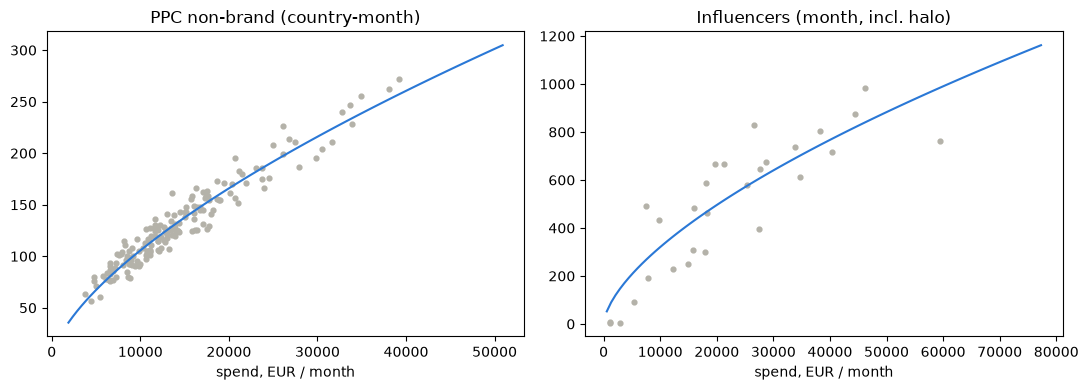

In [12]:
orders_ = pd.read_csv(OUT / "order_value.csv", parse_dates=["order_ts"])[["order_id", "order_ts", "country"]]
spend = pd.read_parquet(CLEAN / "sim_spend.parquet")
spend["month"] = spend.date.dt.to_period("M")
mk = markov_orders.merge(orders_, on="order_id")
mk["month"] = mk.order_ts.dt.to_period("M")

def power(x, a, b):
    return a * np.power(x, b)

# PPC non-brand: country x month points
nb_s = spend[spend.channel == "PPC Non-brand"].groupby(["country", "month"]).spend_eur.sum()
nb_o = mk[mk.channel == "PPC Non-brand"].groupby(["country", "month"]).credit.sum()
nb = pd.concat([nb_s, nb_o], axis=1).dropna()
nb = nb[(nb.index.get_level_values("month") > pd.Period("2024-05")) & (nb.index.get_level_values("month") < pd.Period("2026-10"))]
(a_nb, b_nb), _ = curve_fit(power, nb.spend_eur, nb.credit, p0=[1, .7])

# influencers: monthly total, claimed genuine orders x halo multiplier
co = pd.read_csv(OUT / "code_usage_weekly.csv", parse_dates=["week"])
inf_s = spend[spend.channel == "Influencers"].groupby("month").spend_eur.sum()
cl = con.execute(f'''
    SELECT date_trunc('month', o.ts) AS month, COUNT(*) AS orders
    FROM read_csv_auto('{(OUT / "order_value.csv").as_posix()}') v
    JOIN read_parquet('{(CLEAN / "sim_orders.parquet").as_posix()}') o USING (order_id)
    WHERE (o.coupon_code LIKE 'CR%' AND v.last_click_channel <> 'Affiliates - Coupon')
       OR v.last_click_channel = 'Influencers'
    GROUP BY 1
''').df()
cl["month"] = pd.to_datetime(cl.month).dt.to_period("M")
inf_curve = pd.concat([inf_s, cl.set_index("month").orders * halo_multiplier], axis=1).dropna()
inf_curve = inf_curve[(inf_curve.index > pd.Period("2024-05")) & (inf_curve.index < pd.Period("2026-10"))]
(a_in, b_in), _ = curve_fit(power, inf_curve.spend_eur, inf_curve.orders, p0=[1, .7])

print(f"PPC non-brand: orders = {a_nb:.3f} * spend^{b_nb:.2f}   (per country-month)")
print(f"Influencers:   orders = {a_in:.3f} * spend^{b_in:.2f}   (per month, incl. halo)")

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, d, (a, b), ycol, t in ((axes[0], nb, (a_nb, b_nb), "credit", "PPC non-brand (country-month)"),
                               (axes[1], inf_curve, (a_in, b_in), "orders", "Influencers (month, incl. halo)")):
    ax.scatter(d.spend_eur, d[ycol], s=12, c="#B4B2A9")
    x = np.linspace(d.spend_eur.min() * .5, d.spend_eur.max() * 1.3, 100)
    ax.plot(x, power(x, a, b), c="#2A78D6"); ax.set_title(t); ax.set_xlabel("spend, EUR / month")
plt.tight_layout(); plt.show()

In [13]:
# Marginal cost of one more order (EUR) at the current average monthly spend
nb_month = nb.groupby("month").spend_eur.sum().mean()          # total across countries
nb_per_country = nb.spend_eur.mean()
inf_month = inf_curve.spend_eur.mean()

def marginal_cost(a, b, x):            # 1 / derivative of a*x^b
    return 1 / (a * b * x ** (b - 1))

mc_nb = marginal_cost(a_nb, b_nb, nb_per_country)
mc_in = marginal_cost(a_in, b_in, inf_month)

# brand ads: cost per incremental order = spend / (brand last-click orders x incrementality)
cd = pd.read_csv(OUT / "channel_daily.csv", parse_dates=["date"])
cd = cd[(cd.date >= "2025-11-01")]      # last 12 months
brand_spend = cd[cd.channel == "PPC Brand"].spend_eur.sum()
brand_orders = cd[cd.channel == "PPC Brand"].orders_last_click.sum()
cpio_brand = brand_spend / (brand_orders * incr)

aff = pd.read_csv(OUT / "affiliate_scorecard.csv")
cp = aff[aff.type == "coupon"]
cpio_coupon = cp.commission_eur.sum() / (cp.last_click_orders.sum() * (1 - (cp.share_cart_already_started * cp.last_click_orders).sum() / cp.last_click_orders.sum()))

costs = pd.DataFrame([
    ("PPC Brand", brand_spend / brand_orders, cpio_brand, "geo test incrementality"),
    ("Affiliates - Coupon", cp.commission_eur.sum() / cp.last_click_orders.sum(), cpio_coupon, "orders without a cart already started"),
    ("PPC Non-brand", np.nan, mc_nb, "response curve, marginal"),
    ("Influencers", np.nan, mc_in, "response curve incl. halo, marginal"),
], columns=["channel", "cost_per_last_click_order", "cost_per_incremental_order", "method"])
costs.to_csv(OUT / "incremental_cost.csv", index=False)
costs.round(1)

,channel,cost_per_last_click_order,cost_per_incremental_order,method
0,PPC Brand,11.8,83.1,geo test incrementality
1,Affiliates - Coupon,20.8,47.1,orders without a cart already started
2,PPC Non-brand,NaN,164.7,"response curve, marginal"
3,Influencers,NaN,66.6,"response curve incl. halo, marginal"


In [14]:
# Reallocation at the same total budget, over the last 12 months:
# - stop paying coupon-site commission on sales where the buyer had already started a cart (already decided)
# - trim PPC non-brand by 20% in every country (its marginal order is the most expensive)
# - put the money into creators, evaluated on the influencer response curve
months = 12
n_countries = nb.index.get_level_values("country").nunique()
share_period = (cd.date.max() - cd.date.min()).days / (pd.Timestamp("2026-10-31") - pd.Timestamp("2024-05-01")).days
cart_share = (cp.share_cart_already_started * cp.last_click_orders).sum() / cp.last_click_orders.sum()
coupon_save = cp.commission_eur.sum() * share_period * cart_share
orders_lost_coupon = 0.10 * cp.last_click_orders.sum() * share_period * cart_share   # assume 10% would not buy without the code
nb_cut = 0.20
nb_save = months * n_countries * nb_per_country * nb_cut
orders_lost_nb = months * n_countries * (power(nb_per_country, a_nb, b_nb) - power(nb_per_country * (1 - nb_cut), a_nb, b_nb))
moved = coupon_save + nb_save
gain_inf = months * (power(inf_month + moved / months, a_in, b_in) - power(inf_month, a_in, b_in))
realloc = pd.DataFrame([
    ("1 · Coupons: no commission if cart started", -coupon_save, -orders_lost_coupon),
    ("2 · PPC non-brand -20%", -nb_save, -orders_lost_nb),
    ("3 · Creators: money moved", moved, gain_inf),
], columns=["move", "budget_change_eur_12m", "incremental_orders_12m"])
net = realloc.incremental_orders_12m.sum()
realloc.loc[len(realloc)] = ("Net, same total budget", realloc.budget_change_eur_12m.sum(), net)
realloc.to_csv(OUT / "reallocation.csv", index=False)
print(f"Moving EUR {moved:,.0f} over 12 months -> {net:+,.0f} incremental orders at the same budget "
      f"({net / (cd.orders_last_click.sum()):+.1%} of orders)")
realloc.round(0)

Moving EUR 305,014 over 12 months -> +2,144 incremental orders at the same budget (+4.1% of orders)


,move,budget_change_eur_12m,incremental_orders_12m
0,1 · Coupons: no commission if cart started,-99071.0,-477.0
1,2 · PPC non-brand -20%,-205943.0,-1298.0
2,3 · Creators: money moved,305014.0,3919.0
3,"Net, same total budget",0.0,2144.0


In [15]:
# Curves for Power BI: predicted monthly orders across a spend range, with today's spend marked
grid = []
for ch, (a, b), cur, scale in (("PPC Non-brand", (a_nb, b_nb), nb_per_country, len(nb.index.get_level_values("country").unique())),
                               ("Influencers", (a_in, b_in), inf_month, 1)):
    for f in np.linspace(.2, 2.5, 47):
        x = cur * f
        grid.append((ch, x * scale, power(x, a, b) * scale, marginal_cost(a, b, x), abs(f - 1) < 1e-9))
curves = pd.DataFrame(grid, columns=["channel", "monthly_spend_eur", "monthly_orders", "marginal_cost_eur", "is_current"])
curves.to_csv(OUT / "response_curves.csv", index=False)

## 5 · Anomaly detection

Two simple, explainable rules.

(a) **Tracking**: the daily share of duplicated events is normally ~0. A day above 1% means a tag fired twice.
A rolling robust z-score (distance to the 28-day median, in median absolute deviations) also flags unusual raw volumes, but those are often real (a big video), so they are shown, not flagged.

For (b) weekly promo-code uses per creator, a simpler rule: a week is suspicious when the code is used 10+ times
**with no video in the previous 4 weeks**; a creator is flagged when this happens in at least 3 of 4 consecutive weeks.

In [16]:
def robust_z(s, window=28):
    med = s.rolling(window, center=True, min_periods=7).median()
    mad = (s - med).abs().rolling(window, center=True, min_periods=7).median() * 1.4826
    return (s - med) / mad.replace(0, np.nan)

ev_daily = pd.read_csv(OUT / "dq_daily_events.csv", parse_dates=["date"]).set_index("date")
tracking = ev_daily[ev_daily.duplicate_rate > 0.01][["raw_events", "clean_events", "duplicate_rate"]]
print("Tracking anomalies (duplicate rate > 1%):"); print(tracking.round(3))
z = robust_z(ev_daily.raw_events)
print("\nHigh raw volume days (robust z > 5), for information:"); print(ev_daily[z > 5].raw_events.head())

cu = pd.read_csv(OUT / "code_usage_weekly.csv", parse_dates=["week"]).sort_values(["creator_id", "week"])
cu["videos_last_4w"] = cu.groupby("creator_id").videos.transform(lambda s: s.rolling(4, min_periods=1).sum())
cu["flag"] = (cu.videos_last_4w == 0) & (cu.code_orders >= 10)
# persistent = suspicious in at least 3 of the last 4 weeks; the leak is dated at the first such week
cu["persistent"] = cu.groupby("creator_id").flag.transform(lambda s: s.astype(int).rolling(4, min_periods=4).sum() >= 3)
first_flag = cu[cu.persistent].groupby("creator_id").agg(first_flag_week=("week", "min"), flagged_weeks=("week", "count"))
first_flag["code_orders_in_flagged_weeks"] = [cu[(cu.creator_id == c) & cu.flag].code_orders.sum() for c in first_flag.index]
print("\nCreators with persistent code use without a video (possible leak):"); print(first_flag)

anomalies = pd.concat([
    tracking.reset_index().assign(type="Tracking events spike", subject="all channels")
            .rename(columns={"date": "period", "raw_events": "value"})[["type", "subject", "period", "value"]],
    first_flag.reset_index().assign(type="Promo code used without a video")
            .rename(columns={"creator_id": "subject", "first_flag_week": "period", "code_orders_in_flagged_weeks": "value"})
            [["type", "subject", "period", "value"]],
])
anomalies.to_csv(OUT / "anomalies.csv", index=False)

Tracking anomalies (duplicate rate > 1%):
            raw_events  clean_events  duplicate_rate
date                                                
2025-06-18        7052          3526             0.5

High raw volume days (robust z > 5), for information:
date
2025-03-14    3193
2025-03-16    3267
2025-06-18    7052
2026-05-27    3291
Name: raw_events, dtype: int64

Creators with persistent code use without a video (possible leak):
           first_flag_week  flagged_weeks  code_orders_in_flagged_weeks
creator_id                                                             
CR02            2025-06-30             60                          2315
CR11            2025-12-08             47                          1148
CR18            2026-04-13             29                           626


## 6 · Headline numbers used in the report

In [17]:
q = pd.read_csv(OUT / "channel_quality.csv").set_index("channel")
cs = scorecard
leak = cs[cs.leaked_code_orders > 0].sort_values("leaked_code_orders", ascending=False)
headline = {
    "influencer_share_last_click": inf["Last click"],
    "influencer_share_markov": inf["Markov (data-driven)"],
    "brand_share_last_click": brand["Last click"],
    "brand_share_markov": brand["Markov (data-driven)"],
    "brand_lost_when_off": lost,
    "total_orders_effect": -(1 - np.exp(total_effect)),
    "coupon_share_last_click": coupon["Last click"],
    "coupon_share_markov": coupon["Markov (data-driven)"],
    "brand_incrementality": incr,
    "brand_recaptured": 1 - incr,
    "halo_multiplier": halo_multiplier,
    "seo_ltv_24m": q.loc["SEO", "ltv_24m"],
    "ppc_nb_ltv_24m": q.loc["PPC Non-brand", "ltv_24m"],
    "coupon_refund_rate": q.loc["Affiliates - Coupon", "refund_rate_30d"],
    "seo_refund_rate": q.loc["SEO", "refund_rate_30d"],
    "leaked_code_orders": int(cs.leaked_code_orders.sum()),
    "top_leak_creator": leak.creator_id.iloc[0],
    "top_leak_share": leak.leaked_share_of_code.iloc[0],
    "coupon_cart_already": cart_share,
    "ppc_nb_marginal_cost": mc_nb,
    "influencer_marginal_cost": mc_in,
    "realloc_moved_eur": moved,
    "realloc_net_orders": net,
}
pd.Series(headline, name="value").to_frame().to_csv(OUT / "headline.csv")
pd.Series(headline)

influencer_share_last_click         0.018705
influencer_share_markov             0.023571
brand_share_last_click              0.119369
brand_share_markov                  0.109109
brand_lost_when_off                 0.038328
total_orders_effect                -0.045358
coupon_share_last_click             0.165293
coupon_share_markov                 0.083019
brand_incrementality                0.142229
brand_recaptured                    0.857771
halo_multiplier                     1.371193
seo_ltv_24m                       103.839557
ppc_nb_ltv_24m                     76.248266
coupon_refund_rate                   0.12392
seo_refund_rate                     0.055755
leaked_code_orders                      4226
top_leak_creator                        CR02
top_leak_share                       0.66676
coupon_cart_already                 0.558661
ppc_nb_marginal_cost              164.725838
influencer_marginal_cost           66.619126
realloc_moved_eur              305013.974338
realloc_ne